# 03. Defining "viral"

**Problem:** views are heavy-tailed and platform growth changes what a "big" video is.
A fixed threshold would mostly label recent videos as viral.

**Solution:** a relative threshold inside each posting month (the cohort).

| Label | Rule |
|---|---|
| A | views in the top 10% of its month |
| B | views in the top 5% of its month |
| C | top 10% of views and engagement_rate above the month median |

**Choice:** A is the main label. It gives about 10% positives in every split, enough
positives to learn from, and a simple explanation. B is a robustness check.
**Rule:** `views`, `likes`, `comments`, `shares`, `saves`, `downloads` and `engagement_rate`
define or leak the label, so they are never used as features.

In [1]:
from pathlib import Path
import polars as pl

ROOT = Path.cwd().parent
P = ROOT / "data" / "processed"

train = pl.read_parquet(P / "train.parquet").with_columns(pl.lit("train").alias("split"))
val   = pl.read_parquet(P / "validation.parquet").with_columns(pl.lit("validation").alias("split"))
test  = pl.read_parquet(P / "test.parquet").with_columns(pl.lit("test").alias("split"))

df = pl.concat([train, val, test])
print(df.shape)

(59994, 32)


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 59994.0       │
│ null_count ┆ 0.0           │
│ mean       ┆ 9951.125146   │
│ std        ┆ 180899.352899 │
│ min        ┆ 0.0           │
│ 25%        ┆ 174.0         │
│ 50%        ┆ 381.0         │
│ 75%        ┆ 852.0         │
│ max        ┆ 1.4391157e7   │
└────────────┴───────────────┘
shape: (1, 5)
┌───────┬───────┬────────┬────────┬──────────┐
│ p50   ┆ p75   ┆ p90    ┆ p95    ┆ p99      │
│ ---   ┆ ---   ┆ ---    ┆ ---    ┆ ---      │
│ f64   ┆ f64   ┆ f64    ┆ f64    ┆ f64      │
╞═══════╪═══════╪════════╪════════╪══════════╡
│ 381.0 ┆ 852.0 ┆ 2561.0 ┆ 8025.0 ┆ 106255.0 │
└───────┴───────┴────────┴────────┴──────────┘


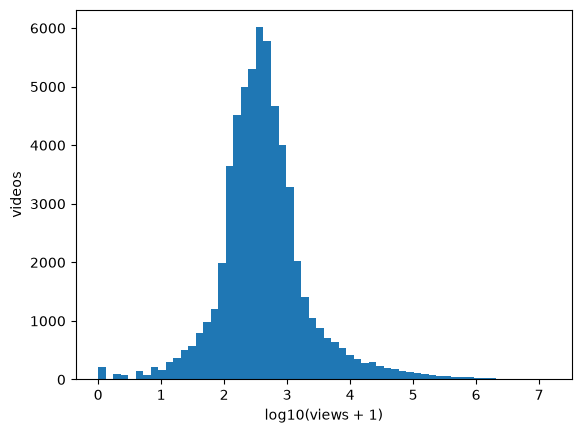

In [2]:
print(df["views"].describe())
print(df.select(
    [pl.col("views").quantile(q).alias(f"p{int(q*100)}") for q in [0.5, 0.75, 0.9, 0.95, 0.99]]
))

import matplotlib.pyplot as plt
import numpy as np
plt.hist(np.log10(df["views"].to_numpy() + 1), bins=60)
plt.xlabel("log10(views + 1)")
plt.ylabel("videos")
plt.show()

In [3]:
df = df.with_columns(pl.col("posted_at").dt.truncate("1mo").alias("cohort"))
sizes = df.group_by("cohort").len().sort("cohort")
print(sizes)

shape: (18, 2)
┌─────────────────────────┬──────┐
│ cohort                  ┆ len  │
│ ---                     ┆ ---  │
│ datetime[ms, UTC]       ┆ u32  │
╞═════════════════════════╪══════╡
│ 2025-01-01 00:00:00 UTC ┆ 3333 │
│ 2025-02-01 00:00:00 UTC ┆ 3333 │
│ 2025-03-01 00:00:00 UTC ┆ 3333 │
│ 2025-04-01 00:00:00 UTC ┆ 3333 │
│ 2025-05-01 00:00:00 UTC ┆ 3333 │
│ …                       ┆ …    │
│ 2026-02-01 00:00:00 UTC ┆ 3333 │
│ 2026-03-01 00:00:00 UTC ┆ 3333 │
│ 2026-04-01 00:00:00 UTC ┆ 3333 │
│ 2026-05-01 00:00:00 UTC ┆ 3333 │
│ 2026-06-01 00:00:00 UTC ┆ 3333 │
└─────────────────────────┴──────┘


In [4]:
df = df.with_columns([
    # A: top 10% of views in the cohort
    (pl.col("views") >= pl.col("views").quantile(0.90).over("cohort")).alias("viral_A"),
    # B: top 5% of views in the cohort
    (pl.col("views") >= pl.col("views").quantile(0.95).over("cohort")).alias("viral_B"),
    # C: top 10% of views AND engagement above the cohort median
    ((pl.col("views") >= pl.col("views").quantile(0.90).over("cohort")) &
     (pl.col("engagement_rate") >= pl.col("engagement_rate").median().over("cohort"))).alias("viral_C"),
])

print(
    df.group_by("split")
      .agg([pl.len().alias("rows"),
            pl.col("viral_A").mean().alias("A"),
            pl.col("viral_B").mean().alias("B"),
            pl.col("viral_C").mean().alias("C")])
)

shape: (3, 5)
┌────────────┬───────┬──────────┬──────────┬──────────┐
│ split      ┆ rows  ┆ A        ┆ B        ┆ C        │
│ ---        ┆ ---   ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ u32   ┆ f64      ┆ f64      ┆ f64      │
╞════════════╪═══════╪══════════╪══════════╪══════════╡
│ train      ┆ 27597 ┆ 0.099685 ┆ 0.05015  ┆ 0.04062  │
│ validation ┆ 14398 ┆ 0.100083 ┆ 0.050424 ┆ 0.035977 │
│ test       ┆ 17999 ┆ 0.101228 ┆ 0.050781 ┆ 0.036669 │
└────────────┴───────┴──────────┴──────────┴──────────┘


## Final label
`is_viral` = 1 if the video is in the top 10% of views of its posting month, else 0.
Saved as `*_labeled.parquet`.

In [5]:
df = df.with_columns(pl.col("viral_A").cast(pl.UInt8).alias("is_viral"))

for name in ["train", "validation", "test"]:
    df.filter(pl.col("split") == name).write_parquet(P / f"{name}_labeled.parquet")